In [8]:
from src import part1_utils
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math

root = Path.cwd().parent
data_dir = root / "data"

In [2]:
with open(data_dir / "trainingI.dat", "r") as training:
    X = []
    Y = []
    for line in training:
        x, y = map(float, line.split())
        X.append(x)
        Y.append(y)
    X = np.array(X)
    Y = np.array(Y)

In [14]:
m = 60
n = 8

A = np.zeros((m, n))
for i in range(m):
    for j in range(n):
        A[i, j] = part1_utils.Legendre_poly(j, X[i])

theta = part1_utils.naive_LSE(A, Y)
display(Math(r"\theta=" + part1_utils.np_to_latex(theta)))
display(Math(r"A=" + part1_utils.np_to_latex(A)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Text(0.5, 0, 'x')

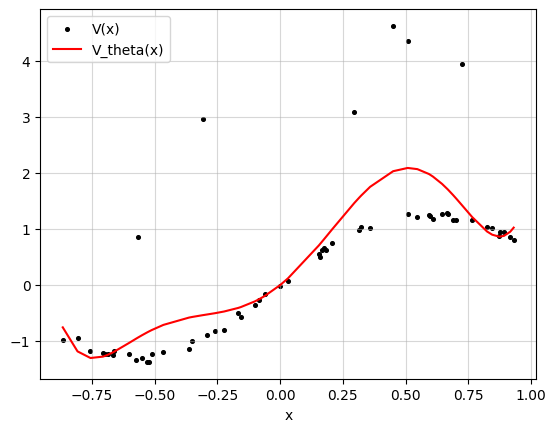

In [4]:
v_estimate_vec = np.array([part1_utils.V_estimate(theta, x) for x in X])

plt.scatter(X, Y, label="V(x)", color="black", s=7)
plt.plot(X, v_estimate_vec, label="V_theta(x)", color="red")

plt.legend()
plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Least squares estimation versus ground truth")

Text(0.5, 0, 'x')

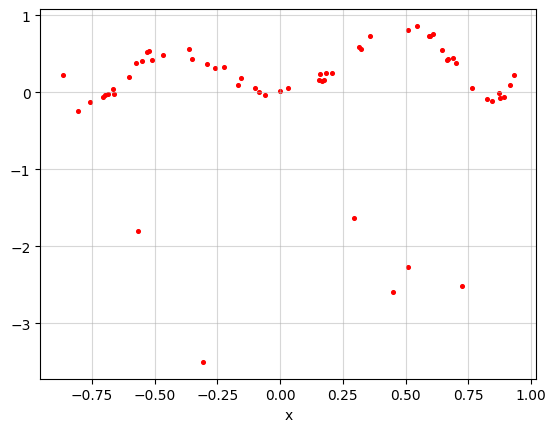

In [5]:
res = A @ theta - Y

plt.scatter(X, res, s=7, color="red")

plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Residuals of LSE")